# BraTS 2024 - Slice Dataset Generation and Export

This notebook handles:
1. Mounting Google Drive and installing the `brain_mri` package.
2. Loading preprocessing configuration and patient splits (`train` / `validate` / `test`).
3. **Single patient sanity check:** validating slice extraction, PyTorch tensors, and visualization.
4. **Full dataset export:** saving all patient 2D slices as `.pt` files to disk.

## 1. Mount Google Drive and environment setup

In [9]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import os
from pathlib import Path

repo_path = Path("/content/BraTS_thesis")
branch = "minvalue_norm"

if not repo_path.exists():
    !git clone -b {branch} https://github.com/AdaBro24/BraTS_thesis.git {repo_path}
else:
    !git -C {repo_path} fetch origin
    !git -C {repo_path} checkout {branch}
    !git -C {repo_path} pull origin {branch}

!pip install -e /content/BraTS_thesis

remote: Enumerating objects: 19, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 10 (delta 7), reused 10 (delta 7), pack-reused 0 (from 0)
Unpacking objects: 100% (10/10), 1.88 KiB | 34.00 KiB/s, done.
From https://github.com/AdaBro24/BraTS_thesis
   a0e6721..993836e  minvalue_norm -> origin/minvalue_norm
Already on 'minvalue_norm'
Your branch is behind 'origin/minvalue_norm' by 1 commit, and can be fast-forwarded.
  (use "git pull" to update your local branch)
From https://github.com/AdaBro24/BraTS_thesis
 * branch            minvalue_norm -> FETCH_HEAD
Updating a0e6721..993836e
Fast-forward
 notebooks/01_dataset_generation.ipynb | 67 ++++++++++++++++++++++++++---------
 pyproject.toml                        |  1 +
 requirements.txt                      |  1 +
 src/brain_mri/data/dataset_export.py  | 41 +++++++++++----------
 4 files changed, 75 insertions(+), 35 deletions(-)
Obtaining file:///content/BraTS_thesis
  Inst

## 2. Data paths and configuration

In [14]:
import sys
from pathlib import Path

# Ensure repository src path is available to the current Python kernel
repo_src = Path("/content/BraTS_thesis/src")
if repo_src.exists() and str(repo_src) not in sys.path:
    sys.path.insert(0, str(repo_src))

import torch

from brain_mri import load_data_config
from brain_mri.data.split import get_or_create_splits
from brain_mri.data.slice_extraction import extract_patient_slices
from brain_mri.data.dataset_export import save_patients_to_pt, export_dataset_split

# Google Drive data paths
ZIP_DIR = Path("/content/drive/MyDrive/engineering_thesis/brats")
DATA_ROOT = ZIP_DIR / "unpacked"
GLI_ROOT = DATA_ROOT / "BraTS-GLI" / "training_data1_v2"


# Load preprocessing YAML config
config = load_data_config(Path("/content/BraTS_thesis/configs/data_config.yaml"))
# Update Z boundaries path to Colab workspace
config.paths.z_boundaries = Path("/content/BraTS_thesis/data/patients_z_boundaries.json")

# Load or generate patient splits (train: 70%, val: 15%, test: 15%)
splits_json_path = ZIP_DIR / "data_splits.json"
splits = get_or_create_splits(folder_path=GLI_ROOT, json_path=splits_json_path)

print("Patient count:")
print(f" - Train:      {len(splits['train'])}")
print(f" - Validation: {len(splits['validate'])}")
print(f" - Test:       {len(splits['test'])}")

Patient count:
 - Train:      944
 - Validation: 203
 - Test:       203


## 3. Single patient test (Sanity check and visualization)

Testing patient: BraTS-GLI-02204-104
Extracted 152 slices.
Saved 152 .pt files to /content/test_processed

--- Tensor verification ---
Image shape:       torch.Size([4, 224, 224]), dtype: torch.float32
Mask shape:        torch.Size([224, 224]), dtype: torch.int64
Unique mask labels: [0, 1, 2, 3]
Background value (corner): [0.0, 0.0, 0.0, 0.0]


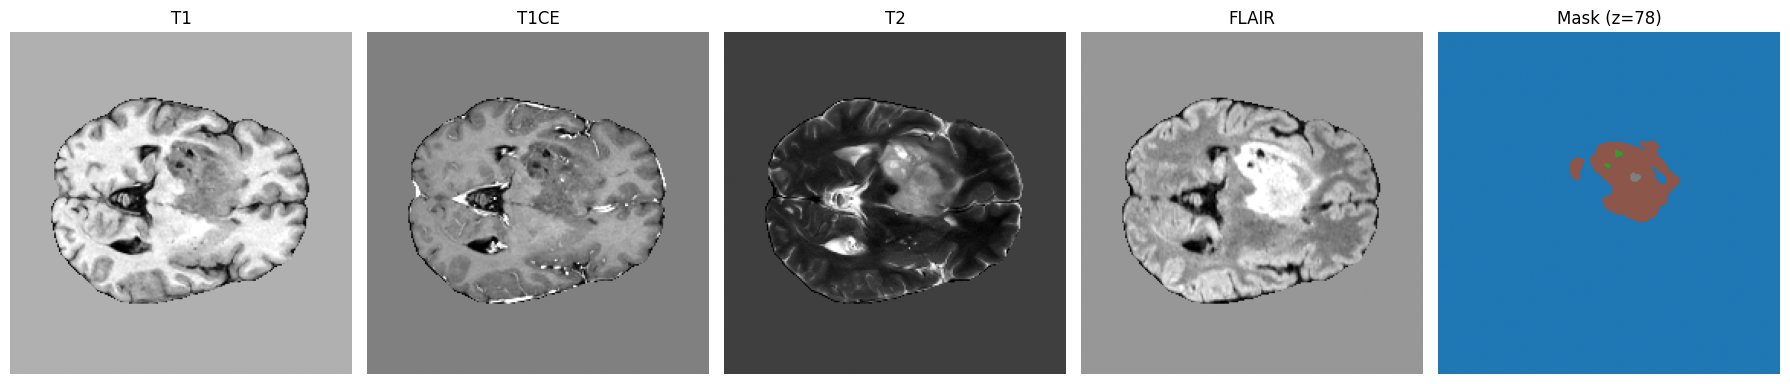

In [15]:
import matplotlib.pyplot as plt

# Select the first training patient for testing
test_patient_id = splits["train"][0]
test_patient_dir = GLI_ROOT / test_patient_id
print(f"Testing patient: {test_patient_id}")

# Extract slices
slices = extract_patient_slices(test_patient_dir, config=config)
print(f"Extracted {len(slices)} slices.")

# Save slices to a temporary test directory
test_output_dir = Path("/content/test_processed")
saved_files = save_patients_to_pt(slices, test_output_dir)
print(f"Saved {len(saved_files)} .pt files to {test_output_dir}")

# Inspect a middle slice (where tumor is usually present)
sample_file = saved_files[len(saved_files) // 2]
data = torch.load(sample_file, weights_only=True)

img = data["image"]  # (4, 224, 224)
mask = data["mask"]  # (224, 224)

print("\n--- Tensor verification ---")
print(f"Image shape:       {img.shape}, dtype: {img.dtype}")
print(f"Mask shape:        {mask.shape}, dtype: {mask.dtype}")
print(f"Unique mask labels: {torch.unique(mask).tolist()}")
print(f"Background value (corner): {img[:, 0, 0].tolist()}")

# Plot all 4 MRI modalities + segmentation mask
modalities = ["T1", "T1CE", "T2", "FLAIR"]
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i in range(4):
    axes[i].imshow(img[i].numpy(), cmap="gray")
    axes[i].set_title(modalities[i])
    axes[i].axis("off")

axes[4].imshow(mask.numpy(), cmap="tab10", vmin=0, vmax=4)
axes[4].set_title(f"Mask (z={data['z_idx']})")
axes[4].axis("off")

plt.tight_layout()
plt.show()

## 4. Full dataset export

Uncomment and run when ready to process all patients to Google Drive (`processed/`).

In [17]:
# Destination directory on Google Drive
PROCESSED_ROOT = ZIP_DIR / "processed"

stats = export_dataset_split(
    data_root=GLI_ROOT,
    splits=splits,
    output_root=PROCESSED_ROOT,
    config=config
)
print("Export summary:", stats)

Extracting train, (944 patients...)


RuntimeError: [enforce fail at inline_container.cc:747] . open file failed with strerror: No such file or directory